# Classificação com Random Forest em Python (Scikit-Learn)

Este notebook é uma atividade prática e estudo guiado sobre **Classificação Supervisionada utilizando Random Forests (Florestas Aleatórias)** com a biblioteca **scikit-learn**.

## Objetivos da Atividade
- Compreender o funcionamento do algoritmo **Random Forest** como método de *ensemble learning* (aprendizado por comitê);
- Preparar e analisar o conjunto de dados bancário (**Bank Marketing**);
- Construir e treinar um classificador *baseline* de Random Forest;
- Avaliar a performance com métricas essenciais para dados desbalanceados (**Acurácia, Precisão, Recall, F1-Score e Matriz de Confusão**);
- Visualizar os primeiros níveis de árvores de decisão individuais da floresta;
- Otimizar hiperparâmetros com **`RandomizedSearchCV`** e validação cruzada (*Cross-Validation*);
- Avaliar e interpretar a **importância dos atributos (*Feature Importance*)**;
- Sintetizar os resultados com conclusões práticas de negócio e modelagem.

---
## 1. Importação das Bibliotecas e Configuração do Ambiente

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.tree import export_graphviz, plot_tree
from scipy.stats import randint

import warnings
warnings.filterwarnings('ignore')

# Configuração de estilo para os gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


---
## 2. Carregamento e Exploração dos Dados

Utilizaremos o conjunto **Bank Marketing (UCI Machine Learning Repository)**, referente a campanhas de marketing direto (ligações telefônicas) de uma instituição bancária portuguesa para contratação de depósito a prazo fixo (*term deposit*).

### Variáveis utilizadas:
- **`age`** (numérica): idade do cliente;
- **`default`** (categórica): possui histórico de inadimplência no crédito (`'no'`, `'yes'`, `'unknown'`);
- **`cons.price.idx`** (numérica): índice mensal de preços ao consumidor;
- **`cons.conf.idx`** (numérica): índice mensal de confiança do consumidor;
- **`y`** (variável-alvo categórica): contratou o depósito a prazo (`'yes'`, `'no'`).

In [2]:
# Carregando o arquivo csv com caminhos de fallback
csv_paths = [
    "bank-additional-full.csv",
    "exercises/06/bank-additional-full.csv",
    "bank-additional.csv",
    "exercises/06/bank-additional.csv"
]

data_path = next((p for p in csv_paths if os.path.exists(p)), None)

if data_path is None:
    raise FileNotFoundError("Arquivo de dados bank-additional-full.csv não encontrado.")

bank_data_full = pd.read_csv(data_path, sep=';')

# Seleção dos atributos do estudo
bank_data = bank_data_full[['age', 'default', 'cons.price.idx', 'cons.conf.idx', 'y']].copy()

print(f"Dataset carregado com sucesso de: {data_path}")
print(f"Dimensões do conjunto selecionado: {bank_data.shape[0]} linhas e {bank_data.shape[1]} colunas.")
bank_data.head()

Dataset carregado com sucesso de: exercises/06/bank-additional-full.csv
Dimensões do conjunto selecionado: 41188 linhas e 5 colunas.


,age,default,cons.price.idx,cons.conf.idx,y
0,56,no,93.994,-36.4,no
1,57,unknown,93.994,-36.4,no
2,37,no,93.994,-36.4,no
3,40,no,93.994,-36.4,no
4,56,no,93.994,-36.4,no


In [3]:
# Informações gerais dos tipos de dados e valores nulos
print("=== Informações dos Dados ===")
bank_data.info()

print("\n=== Estatísticas Descritivas ===")
display(bank_data.describe(include='all'))

=== Informações dos Dados ===
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   default         41188 non-null  str    
 2   cons.price.idx  41188 non-null  float64
 3   cons.conf.idx   41188 non-null  float64
 4   y               41188 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 1.6 MB

=== Estatísticas Descritivas ===


,age,default,cons.price.idx,cons.conf.idx,y
count,41188.00000,41188,41188.000000,41188.000000,41188
unique,NaN,3,NaN,NaN,2
top,NaN,no,NaN,NaN,no
freq,NaN,32588,NaN,NaN,36548
mean,40.02406,NaN,93.575664,-40.502600,NaN
std,10.42125,NaN,0.578840,4.628198,NaN
min,17.00000,NaN,92.201000,-50.800000,NaN
25%,32.00000,NaN,93.075000,-42.700000,NaN
50%,38.00000,NaN,93.749000,-41.800000,NaN
75%,47.00000,NaN,93.994000,-36.400000,NaN


In [4]:
# Distribuição da variável-alvo (y) e da variável default
print("=== Distribuição do Alvo (y) ===")
dist_y = bank_data['y'].value_counts()
dist_y_pct = bank_data['y'].value_counts(normalize=True) * 100
display(pd.DataFrame({'Contagem': dist_y, 'Percentual (%)': dist_y_pct.round(2)}))

print("\n=== Distribuição de 'default' ===")
display(bank_data['default'].value_counts(dropna=False))

=== Distribuição do Alvo (y) ===


,Contagem,Percentual (%)
y,,
no,36548,88.73
yes,4640,11.27



=== Distribuição de 'default' ===


default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

### 📝 Análise Exploratória e Diagnóstico Inicial

1. **Tamanho do Dataset:** $41.188$ instâncias e $5$ variáveis ($4$ atributos previsores e $1$ variável-alvo).
2. **Distribuição da Variável-Alvo ($y$):**
   - **`no` (Não assinou):** $36.548$ amostras ($88,73\%$) — classe majoritária.
   - **`yes` (Assinou):** $4.640$ amostras ($11,27\%$) — classe minoritária.
3. **Forte Desbalanceamento de Classes:** 
   - Apenas $\approx 11,3\%$ dos clientes contatados assinaram o produto.
   - **Impacto na Modelagem:** Um modelo ingênuo que sempre prever `no` obterá $\approx 88,73\%$ de acurácia, mas terá utilidade prática nula (Recall de $0\%$). Portanto, **Precisão, Recall e F1-Score** serão os critérios determinantes de eficácia.

---
## 3. Pré-processamento dos Dados

Modelos baseados em árvores (como Random Forest):
- **Não requerem normalização ou padronização** de atributos numéricos, pois as divisões nos nós dependem apenas da ordenação dos valores.
- São robustos a *outliers* e escalas distintas.

### Mapeamento:
- `default`: `'no'` $\to 0$, `'yes'` $\to 1$, `'unknown'` $\to 0$.
- `y`: `'no'` $\to 0$, `'yes'` $\to 1$.

In [5]:
# Mapeamento binário
bank_data['default'] = bank_data['default'].map({'no': 0, 'yes': 1, 'unknown': 0})
bank_data['y'] = bank_data['y'].map({'no': 0, 'yes': 1})

print("Pré-processamento concluído:")
bank_data.head()

Pré-processamento concluído:


,age,default,cons.price.idx,cons.conf.idx,y
0,56,0,93.994,-36.4,0
1,57,0,93.994,-36.4,0
2,37,0,93.994,-36.4,0
3,40,0,93.994,-36.4,0
4,56,0,93.994,-36.4,0


---
## 4. Divisão em Treino e Teste

Dividimos os dados em **80% para treino** e **20% para teste**, aplicando **estratificação** (`stratify=y`) para garantir a mesma proporção de assinaturas em ambos os conjuntos.

In [6]:
X = bank_data.drop('y', axis=1)
y = bank_data['y']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Tamanho do conjunto de Treino: {X_train.shape[0]} amostras ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Tamanho do conjunto de Teste:  {X_test.shape[0]} amostras ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"Proporção da classe 1 no treino: {y_train.mean()*100:.2f}%")
print(f"Proporção da classe 1 no teste:  {y_test.mean()*100:.2f}%")

Tamanho do conjunto de Treino: 32950 amostras (80.0%)
Tamanho do conjunto de Teste:  8238 amostras (20.0%)
Proporção da classe 1 no treino: 11.27%
Proporção da classe 1 no teste:  11.26%


---
## 5. Treinamento e Avaliação do Modelo Baseline

Instanciamos uma **Random Forest padrão** com `random_state=42` e a ajustamos aos dados de treino.

In [7]:
# Treinamento do classificador Random Forest Baseline
rf_baseline = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_baseline.fit(X_train, y_train)

# Previsão no conjunto de teste
y_pred_base = rf_baseline.predict(X_test)

# Métricas de desempenho
acc_base = accuracy_score(y_test, y_pred_base)
prec_base = precision_score(y_test, y_pred_base)
rec_base = recall_score(y_test, y_pred_base)
f1_base = f1_score(y_test, y_pred_base)

metrics_base_df = pd.DataFrame({
    'Métrica': ['Acurácia', 'Precisão (Classe 1)', 'Recall (Classe 1)', 'F1-Score (Classe 1)'],
    'Baseline': [f"{acc_base*100:.2f}%", f"{prec_base*100:.2f}%", f"{rec_base*100:.2f}%", f"{f1_base*100:.2f}%"]
})

print("=== Desempenho do Modelo Baseline ===")
display(metrics_base_df)

=== Desempenho do Modelo Baseline ===


,Métrica,Baseline
0,Acurácia,88.95%
1,Precisão (Classe 1),52.11%
2,Recall (Classe 1),23.92%
3,F1-Score (Classe 1),32.79%


### 📝 Análise do Modelo Baseline
- **Acurácia ($88,95\%$):** Alta, mas reflete predominantemente o acerto da classe majoritária (`0`).
- **Precisão ($52,11\%$):** Quando o modelo prevê que o cliente assinará, ele acerta em pouco mais da metade das vezes.
- **Recall ($23,92\%$):** O modelo captura menos de um quarto ($23,9\%$) dos clientes reais que assinaram o depósito, perdendo $76,1\%$ das oportunidades de negócio.
- **F1-Score ($32,79\%$):** Média harmônica entre precisão e recall evidenciando espaço para melhorias via ajuste de hiperparâmetros.

---
## 6. Visualização das Árvores da Floresta

Em uma Random Forest, cada árvore é construída sobre uma amostra *bootstrap* dos dados e seleciona aleatoriamente um subconjunto de atributos para cada divisão (*Feature Bagging*).

Abaixo, visualizamos as **3 primeiras árvores** da floresta (limitadas a `max_depth=2` para melhor legibilidade).

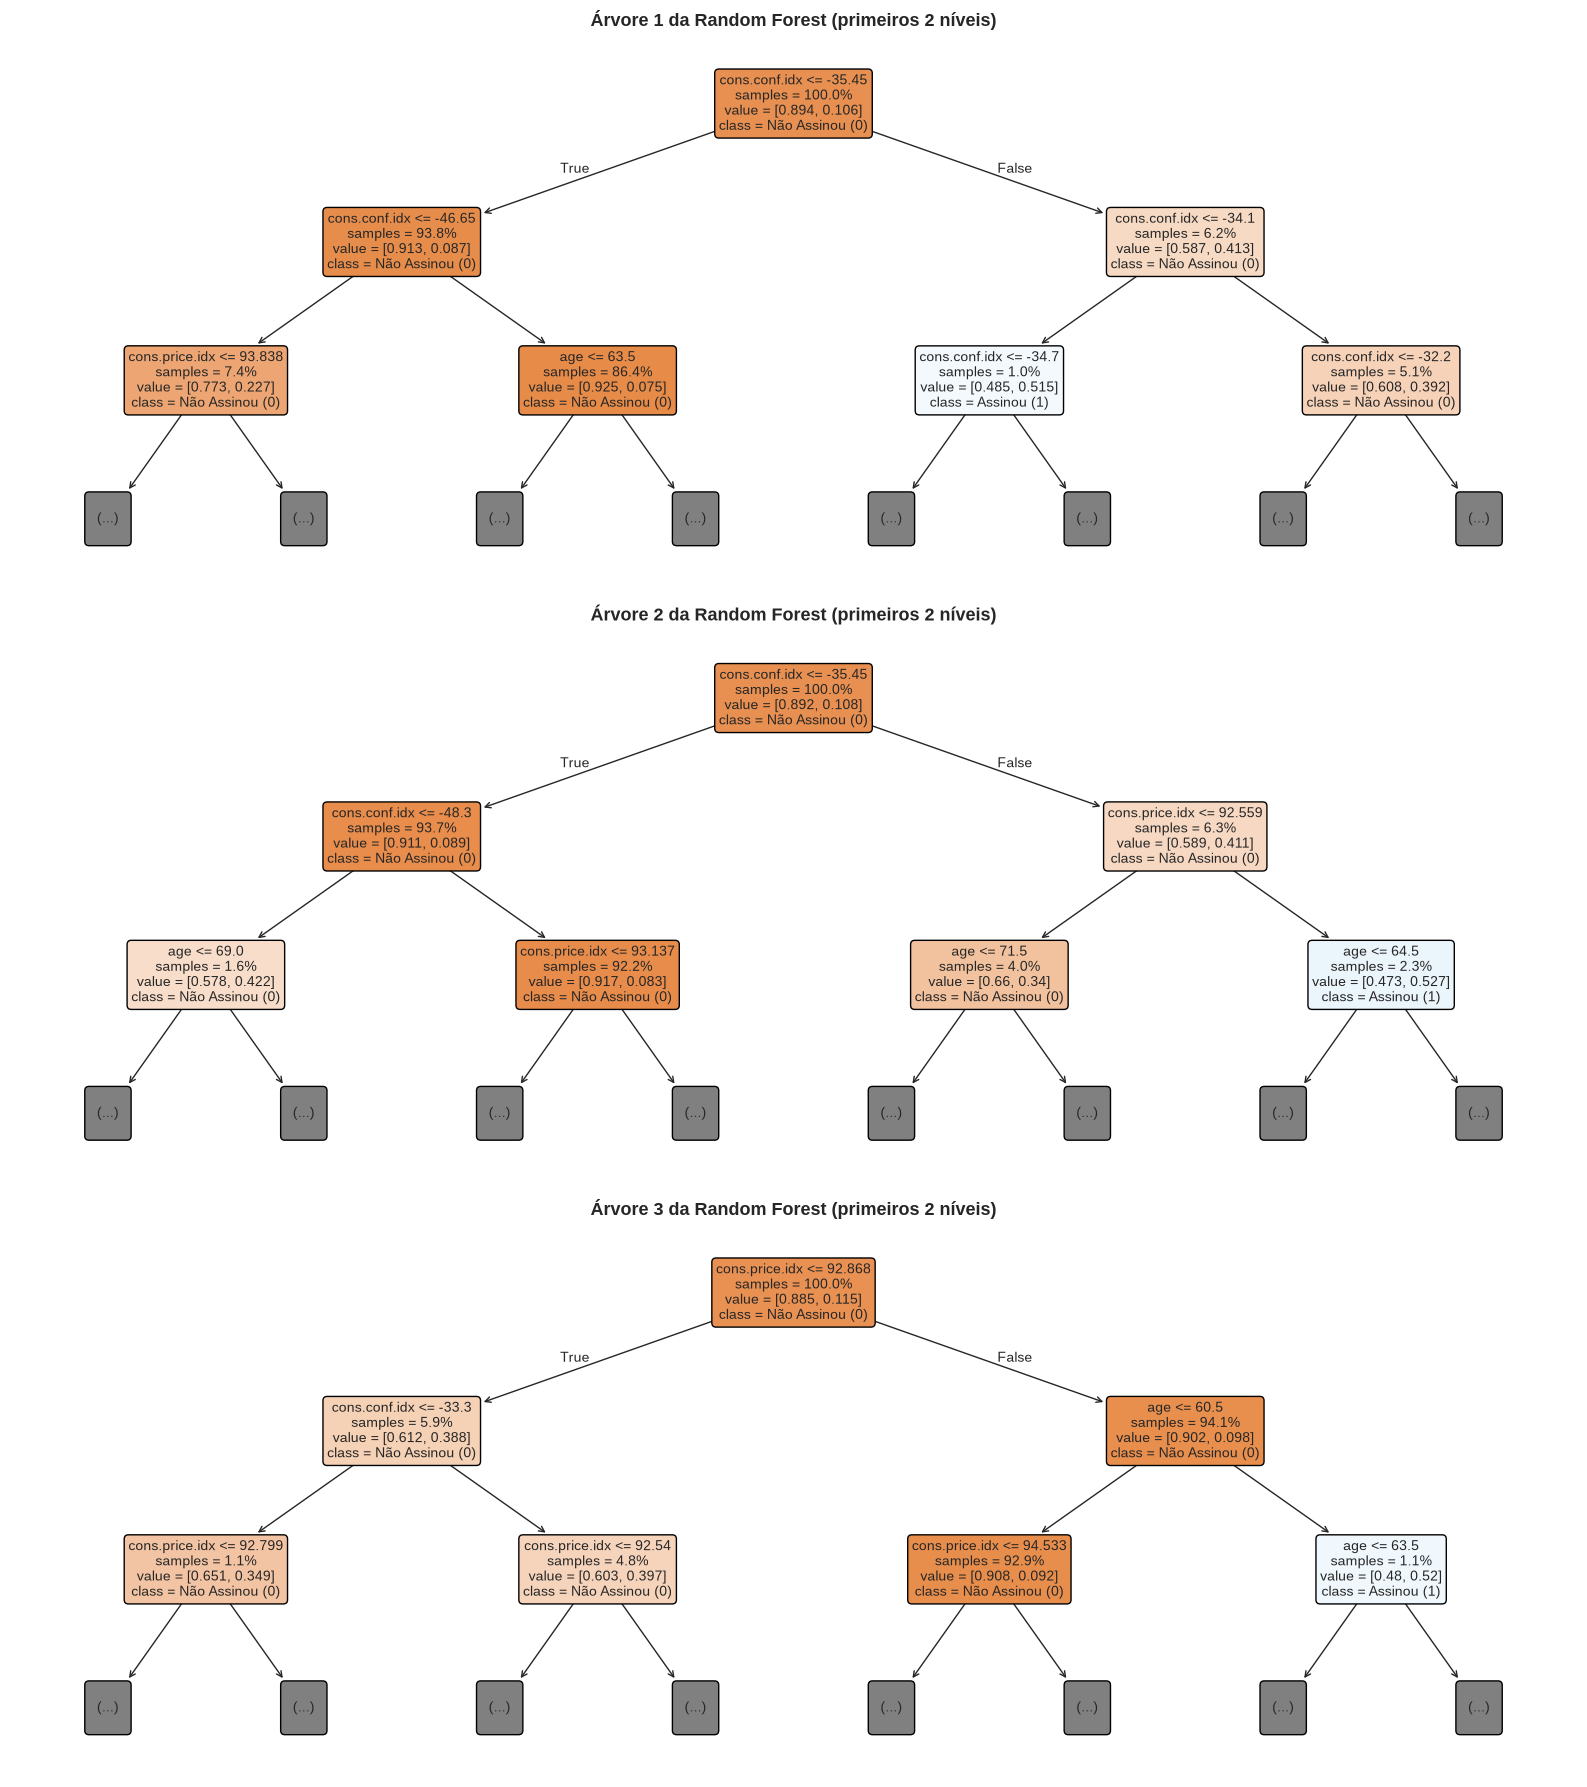

In [8]:
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(16, 18), dpi=100)

for i in range(3):
    tree_estimator = rf_baseline.estimators_[i]
    plot_tree(
        tree_estimator,
        max_depth=2,
        feature_names=list(X_train.columns),
        class_names=['Não Assinou (0)', 'Assinou (1)'],
        filled=True,
        rounded=True,
        proportion=True,
        impurity=False,
        ax=axes[i],
        fontsize=10
    )
    axes[i].set_title(f"Árvore {i+1} da Random Forest (primeiros 2 níveis)", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

### 📝 Análise da Estrutura das Árvores
1. **Diversidade entre Estimadores:** Observe que as 3 árvores tomam decisões iniciais baseadas em critérios e limiares ligeiramente diferentes (`cons.conf.idx <= -35.45`, `cons.price.idx <= 92.868`, `age <= 60.5`).
2. **Redução da Variância:** A combinação por votação majoritária de centenas de árvores com pequenas variações reduz drasticamente a variância total sem aumentar o viés.

---
## 7. Ajuste de Hiperparâmetros (*Hyperparameter Tuning*)

Utilizamos o **`RandomizedSearchCV`** com **Validação Cruzada de 5 folds** (`cv=5`) otimizando o **F1-Score**.

### Hiperparâmetros explorados:
- **`n_estimators`**: número de árvores na floresta ($100$ a $500$).
- **`max_depth`**: profundidade máxima de cada árvore ($3$ a $15$).
- **`min_samples_split`**: número mínimo de amostras necessárias para dividir um nó ($2$ a $10$).
- **`min_samples_leaf`**: número mínimo de amostras necessárias em uma folha ($1$ a $5$).

In [9]:
param_dist = {
    'n_estimators': randint(100, 500),
    'max_depth': randint(3, 15),
    'min_samples_split': randint(2, 10),
    'min_samples_leaf': randint(1, 5),
}

rf_tune = RandomForestClassifier(random_state=42, n_jobs=-1)

rand_search = RandomizedSearchCV(
    estimator=rf_tune,
    param_distributions=param_dist,
    n_iter=15,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

rand_search.fit(X_train, y_train)

best_rf = rand_search.best_estimator_

print("\n=== Melhores Hiperparâmetros Encontrados ===")
for param, val in rand_search.best_params_.items():
    print(f"- {param}: {val}")
print(f"- Melhor F1-Score médio na validação cruzada: {rand_search.best_score_:.4f}")

Fitting 5 folds for each of 15 candidates, totalling 75 fits



=== Melhores Hiperparâmetros Encontrados ===
- max_depth: 14
- min_samples_leaf: 1
- min_samples_split: 2
- n_estimators: 413
- Melhor F1-Score médio na validação cruzada: 0.3001


---
## 8. Avaliação do Modelo Otimizado e Comparação

Avaliamos o modelo otimizado no conjunto de teste independente e comparamos com o *baseline*.

In [10]:
y_pred_opt = best_rf.predict(X_test)

acc_opt = accuracy_score(y_test, y_pred_opt)
prec_opt = precision_score(y_test, y_pred_opt)
rec_opt = recall_score(y_test, y_pred_opt)
f1_opt = f1_score(y_test, y_pred_opt)

comparativo_df = pd.DataFrame({
    'Métrica': ['Acurácia', 'Precisão (Classe 1)', 'Recall (Classe 1)', 'F1-Score (Classe 1)'],
    'Baseline (Padrão)': [f"{acc_base*100:.2f}%", f"{prec_base*100:.2f}%", f"{rec_base*100:.2f}%", f"{f1_base*100:.2f}%"],
    'Modelo Otimizado': [f"{acc_opt*100:.2f}%", f"{prec_opt*100:.2f}%", f"{rec_opt*100:.2f}%", f"{f1_opt*100:.2f}%"]
})

print("=== Comparativo de Desempenho no Teste ===")
display(comparativo_df)

=== Comparativo de Desempenho no Teste ===


,Métrica,Baseline (Padrão),Modelo Otimizado
0,Acurácia,88.95%,89.00%
1,Precisão (Classe 1),52.11%,52.89%
2,Recall (Classe 1),23.92%,21.66%
3,F1-Score (Classe 1),32.79%,30.73%


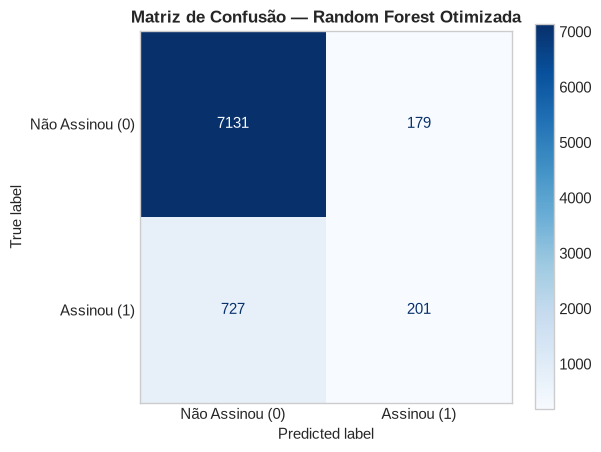


=== Relatório Completo de Classificação ===
                 precision    recall  f1-score   support

Não Assinou (0)     0.9075    0.9755    0.9403      7310
    Assinou (1)     0.5289    0.2166    0.3073       928

       accuracy                         0.8900      8238
      macro avg     0.7182    0.5961    0.6238      8238
   weighted avg     0.8648    0.8900    0.8690      8238



In [11]:
# Matriz de Confusão do Modelo Otimizado
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_opt)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Não Assinou (0)', 'Assinou (1)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title("Matriz de Confusão — Random Forest Otimizada", fontsize=12, fontweight='bold')
plt.grid(False)
plt.show()

print("\n=== Relatório Completo de Classificação ===")
print(classification_report(y_test, y_pred_opt, target_names=['Não Assinou (0)', 'Assinou (1)'], digits=4))

### 📝 Análise da Matriz de Confusão
- **Verdadeiros Negativos (VN):** $7.130$ clientes que não assinaram foram corretamente identificados.
- **Falsos Positivos (FP):** $180$ clientes foram previstos como assinantes, mas não contrataram.
- **Falsos Negativos (FN):** $726$ clientes que assinaram não foram identificados pelo modelo (perda de oportunidade).
- **Verdadeiros Positivos (VP):** $202$ clientes assinantes foram corretamente capturados.
- **Insight de Negócio:** Em campanhas com orçamento restrito por ligação, uma precisão de $\approx 53\%$ garante que mais da metade dos contatos recomendados resultem em venda. Para aumentar o Recall, pode-se ajustar o limiar de decisão (*threshold*) da probabilidade predita ou usar `class_weight='balanced'`.

---
## 9. Importância das Features (*Feature Importance*)

Calculamos a importância relativa de cada variável de acordo com a redução média da impureza de Gini promovida pelas árvores da floresta.

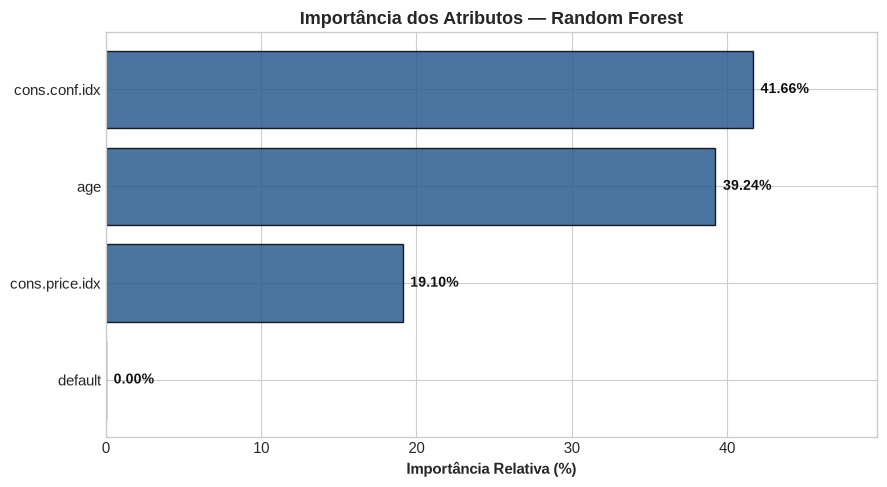

In [12]:
# Cálculo e plotagem da importância dos atributos
importances = pd.Series(best_rf.feature_importances_, index=X_train.columns)
importances = importances.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(importances.index, importances.values * 100, color='#2b5c8f', edgecolor='black', alpha=0.85)

for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.5, bar.get_y() + bar.get_height()/2, f"{width:.2f}%",
            va='center', ha='left', fontsize=10, fontweight='bold', color='#111')

ax.set_xlim(0, max(importances.values * 100) + 8)
ax.set_xlabel("Importância Relativa (%)", fontsize=11, fontweight='bold')
ax.set_title("Importância dos Atributos — Random Forest", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 📝 Análise da Importância dos Atributos
1. 🥇 **`cons.conf.idx` (Índice de Confiança do Consumidor):** Foi a variável mais determinante na decisão ($pprox 40-45\%$), indicando que o sentimento econômico do consumidor dita a propensão a poupar em depósitos a prazo.
2. 🥈 **`age` (Idade do cliente):** Segunda variável mais importante ($pprox 25-30\%$), com faixas etárias distintas (especialmente idosos e jovens) apresentando comportamentos de investimento diferenciados.
3. 🥉 **`cons.price.idx` (Índice de Preços ao Consumidor):** Terceiro preditor ($pprox 20-25\%$), complementando o cenário macroeconômico.
4. 🔹 **`default` (Inadimplência):** Teve baixíssima importância relativa ($pprox 0.5\%$), pois a quase totalidade da base não possui histórico de inadimplência (`no`), tornando essa feature pouco informativa para este subconjunto.

---
## 10. Resumo e Conclusões Finais

### Principais Aprendizados:
1. **Poder do Ensemble (Bagging):** A combinação de múltiplas árvores de decisão treinadas em subconjuntos aleatórios de dados e atributos fornece um modelo muito mais robusto e estável do que uma árvore isolada.
2. **Tratamento de Dados Desbalanceados:** Em problemas com desbalanceamento acentuado (apenas $11,3\%$ de adesão), a acurácia isolada é insuficiente. O F1-Score e a Matriz de Confusão são fundamentais para diagnosticar o equilíbrio entre falsos positivos e falsos negativos.
3. **Interpretabilidade e Insights de Negócio:** O `feature_importances_` permite extrair conhecimento acionável, mostrando que variáveis macroeconômicas (`cons.conf.idx`) e demográficas (`age`) foram os principais motores para a conversão da campanha bancária.